In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('beam_deflection_data.csv')
print(df.head(5))
print(df.shape)
print(df.columns.tolist())

   Beam ID  Total Length (m)  Load (kN)        E (Pa)  I (m⁴)  Position x (m)  \
0        1              5.62       72.8  2.000000e+11  0.0003           0.000   
1        1              5.62       72.8  2.000000e+11  0.0003           0.281   
2        1              5.62       72.8  2.000000e+11  0.0003           0.562   
3        1              5.62       72.8  2.000000e+11  0.0003           0.843   
4        1              5.62       72.8  2.000000e+11  0.0003           1.124   

   Deflection (mm)  
0           0.0000  
1           0.6718  
2           1.3300  
3           1.9613  
4           2.5522  
(10500, 7)
['Beam ID', 'Total Length (m)', 'Load (kN)', 'E (Pa)', 'I (m⁴)', 'Position x (m)', 'Deflection (mm)']


In [4]:
target = df.columns[-1]
y = df[target]
X = df.drop(columns=['Beam ID', target])



print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target variable:", target)

X shape: (10500, 5)
y shape: (10500,)
Target variable: Deflection (mm)


In [5]:
from sklearn.model_selection import GroupShuffleSplit
groups = df['Beam ID']

# First split: 70% training, 30% remaining
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(X, y, groups=groups)
)

X_train, X_temp = X.iloc[train_idx], X.iloc[temp_idx]
y_train, y_temp = y.iloc[train_idx], y.iloc[temp_idx]

# Second split: 15% validation, 15% testing
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(X_temp, y_temp, groups=groups.iloc[temp_idx])
)

X_val, X_test = X_temp.iloc[val_idx], X_temp.iloc[test_idx]
y_val, y_test = y_temp.iloc[val_idx], y_temp.iloc[test_idx]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (7350, 5)
Validation: (1575, 5)
Test: (1575, 5)


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)



class beamNN(nn.Module):

    def __init__(self):
        super().__init__()

        

        self.network = nn.Sequential(
            nn.Linear(5, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
           
        )
        

    def forward(self, x):
        return self.network(x)



model = beamNN().to(device)

print(model)

Using device: cuda
beamNN(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [7]:
import numpy as np

# Calculate statistics from training data only
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_std = X_std.replace(0, 1)

y_mean = y_train.mean()
y_std = y_train.std()

# Normalize all datasets using training statistics
X_train_scaled = (X_train - X_mean) / X_std
X_val_scaled = (X_val - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

y_train_scaled = (y_train - y_mean) / y_std
y_val_scaled = (y_val - y_mean) / y_std
y_test_scaled = (y_test - y_mean) / y_std

In [8]:
print("Training input mean:")
print(X_train_scaled.mean())

print("\nTraining input std:")
print(X_train_scaled.std())

print("\nTraining target mean:", y_train_scaled.mean())
print("Training target std:", y_train_scaled.std())

Training input mean:
Total Length (m)    6.109701e-16
Load (kN)           5.413659e-17
E (Pa)              0.000000e+00
I (m⁴)              0.000000e+00
Position x (m)      7.347109e-17
dtype: float64

Training input std:
Total Length (m)    1.0
Load (kN)           1.0
E (Pa)              0.0
I (m⁴)              0.0
Position x (m)      1.0
dtype: float64

Training target mean: 1.933449621115919e-18
Training target std: 1.0


In [9]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert input and target into float32 tensors
X_train_tensor = torch.tensor(X_train_scaled.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled.values.reshape(-1, 1), dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled.values, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled.values.reshape(-1, 1), dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_scaled.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled.values.reshape(-1, 1), dtype=torch.float32)

In [10]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [11]:
criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [12]:
def forward_pass(model, inputs):
    predictions = model(inputs)
    return predictions

In [14]:
def backward_pass(loss, optimizer):
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

In [16]:

epochs = 100

train_losses = []
val_losses = []

best_val_loss = float('inf')
best_epoch = 0

for epoch in range(epochs):

    # -------- TRAINING --------
    model.train()
    running_train_loss = 0.0

    for inputs, targets in train_loader:

        inputs = inputs.to(device)
        targets = targets.to(device)

        # Forward propagation
        predictions = forward_pass(model, inputs)

        # Calculate loss
        loss = criterion(predictions, targets)

        # Backward propagation and weight update
        backward_pass(loss, optimizer)

        running_train_loss += loss.item() * inputs.size(0)

    # Calculate average training loss
    epoch_train_loss = running_train_loss / len(train_loader.dataset)

    # -------- VALIDATION --------
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for inputs, targets in val_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            predictions = model(inputs)
            loss = criterion(predictions, targets)

            running_val_loss += loss.item() * inputs.size(0)

    # Calculate average validation loss
    epoch_val_loss = running_val_loss / len(val_loader.dataset)

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    # Save best model
    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1

        torch.save(model.state_dict(), "best_beam_model.pth")

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {epoch_train_loss:.6f} "
            f"Val Loss: {epoch_val_loss:.6f}"
        )

print(f"\nBest val loss {best_val_loss:.6f} at epoch {best_epoch}")


Epoch [10/100] Train Loss: 0.000481 Val Loss: 0.000576
Epoch [20/100] Train Loss: 0.000499 Val Loss: 0.000655
Epoch [30/100] Train Loss: 0.000406 Val Loss: 0.000513
Epoch [40/100] Train Loss: 0.000384 Val Loss: 0.000451
Epoch [50/100] Train Loss: 0.000420 Val Loss: 0.000451
Epoch [60/100] Train Loss: 0.000370 Val Loss: 0.000430
Epoch [70/100] Train Loss: 0.000385 Val Loss: 0.000401
Epoch [80/100] Train Loss: 0.000379 Val Loss: 0.000354
Epoch [90/100] Train Loss: 0.000359 Val Loss: 0.000400
Epoch [100/100] Train Loss: 0.000369 Val Loss: 0.000435

Best val loss 0.000349 at epoch 99


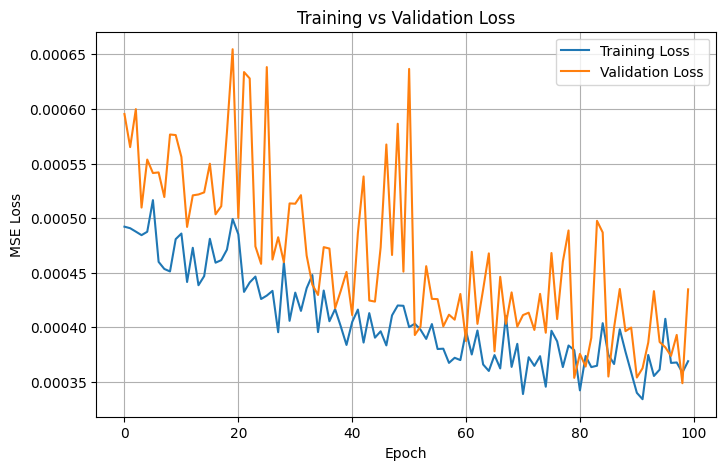

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig("learning_curve.png", dpi=300)
plt.show()

In [18]:
model.load_state_dict(
    torch.load("best_beam_model.pth", map_location=device)
)

model.to(device)
model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [19]:
predictions = []
actual_values = []

with torch.no_grad():

    for inputs, targets in test_loader:

        inputs = inputs.to(device)

        outputs = model(inputs)

        predictions.extend(outputs.cpu().numpy())
        actual_values.extend(targets.numpy())

In [20]:
predictions = np.array(predictions).reshape(-1)
actual_values = np.array(actual_values).reshape(-1)

# Reverse normalization
predictions_mm = predictions * y_std + y_mean
actual_mm = actual_values * y_std + y_mean

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual_mm, predictions_mm)

rmse = np.sqrt(
    mean_squared_error(actual_mm, predictions_mm)
)

relative_l2 = (
    np.linalg.norm(actual_mm - predictions_mm)
    / np.linalg.norm(actual_mm)
)

print("Test Results")
print("--------------------------")
print(f"MAE: {mae:.6f} mm")
print(f"RMSE: {rmse:.6f} mm")
print(f"Relative L2 Error: {relative_l2:.6f}")
print(f"Relative L2 Error (%): {relative_l2 * 100:.4f}%")

Test Results
--------------------------
MAE: 0.070789 mm
RMSE: 0.092137 mm
Relative L2 Error: 0.015901
Relative L2 Error (%): 1.5901%


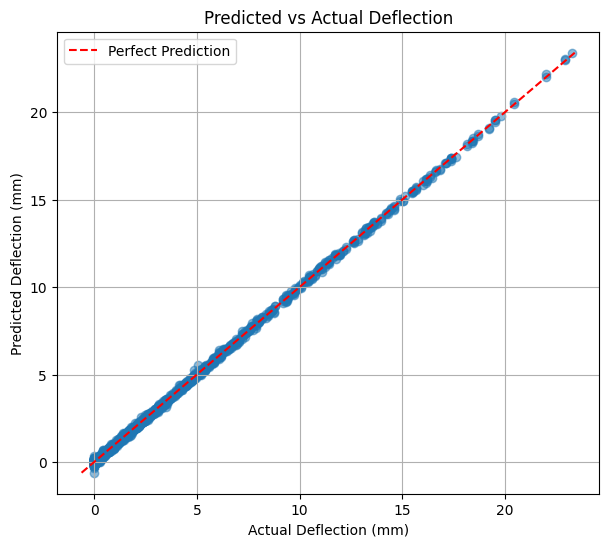

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(actual_mm, predictions_mm, alpha=0.5)

min_val = min(actual_mm.min(), predictions_mm.min())
max_val = max(actual_mm.max(), predictions_mm.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    label="Perfect Prediction"
)

plt.xlabel("Actual Deflection (mm)")
plt.ylabel("Predicted Deflection (mm)")
plt.title("Predicted vs Actual Deflection")
plt.legend()
plt.grid(True)

plt.savefig("predicted_vs_actual.png", dpi=300)
plt.show()

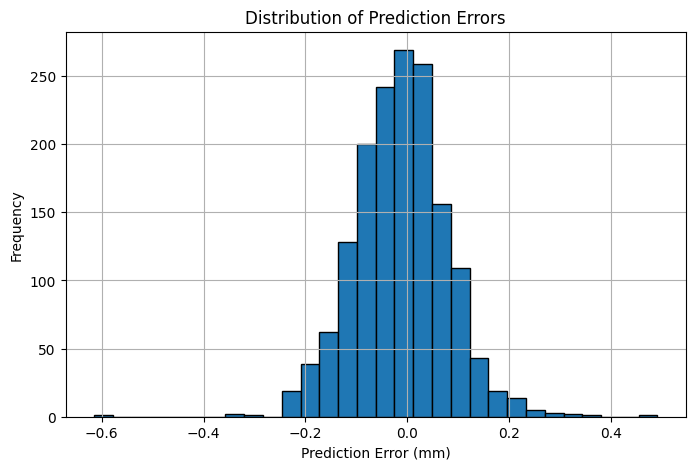

In [23]:
errors = predictions_mm - actual_mm

plt.figure(figsize=(8, 5))
plt.hist(errors, bins=30, edgecolor="black")

plt.xlabel("Prediction Error (mm)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.grid(True)

plt.savefig("error_histogram.png", dpi=300)
plt.show()

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

model.eval()

# Convert test inputs to tensor
X_test_tensor = torch.tensor(
    X_test_scaled.values,
    dtype=torch.float32
).to(device)

# Predict
with torch.no_grad():
    predicted_scaled = model(X_test_tensor).cpu().numpy().flatten()

# Convert predictions back to mm
predicted_mm = predicted_scaled * y_std + y_mean

# Create results DataFrame
test_results = pd.DataFrame({
    "Beam ID": df.loc[X_test.index, "Beam ID"].values,
    "Position x (m)": X_test["Position x (m)"].values,
    "Actual Deflection (mm)": y_test.values,
    "Predicted Deflection (mm)": predicted_mm
})

print(test_results.head())

   Beam ID  Position x (m)  Actual Deflection (mm)  Predicted Deflection (mm)
0        1           0.000                  0.0000                   0.015342
1        1           0.281                  0.6718                   0.725477
2        1           0.562                  1.3300                   1.457758
3        1           0.843                  1.9613                   1.990072
4        1           1.124                  2.5522                   2.453684


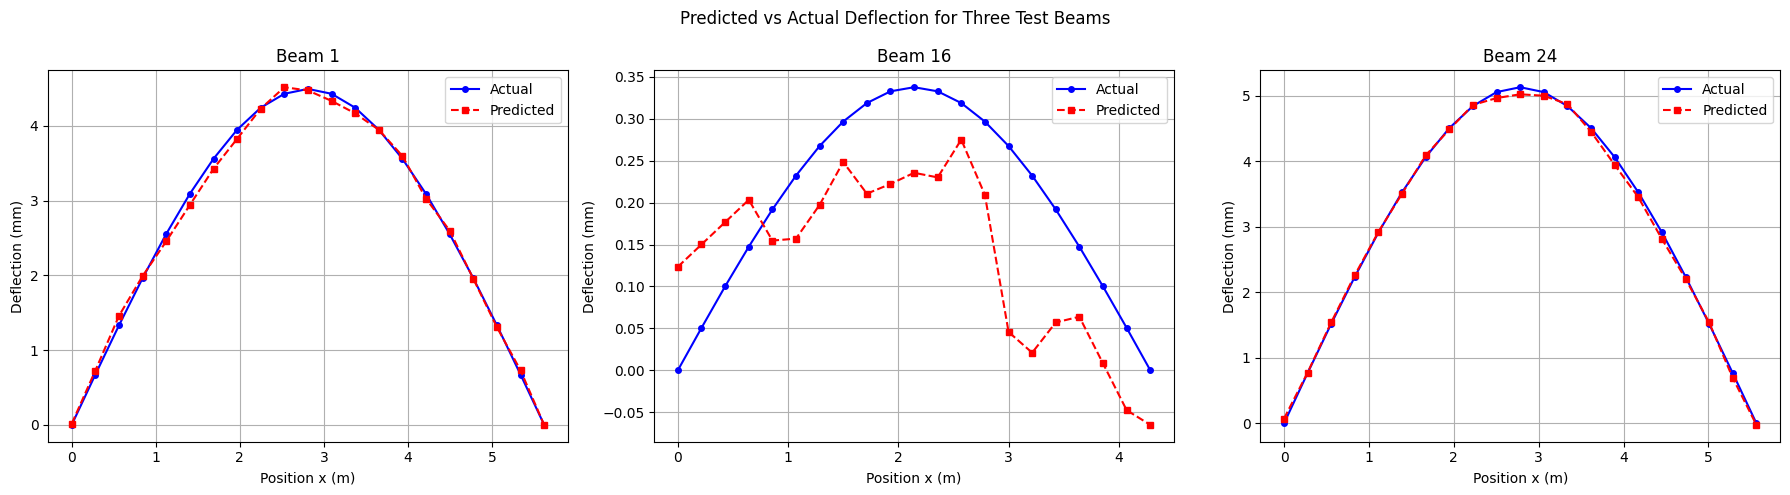

In [25]:
# Select three different test beams
beam_ids = test_results["Beam ID"].unique()[:3]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, beam_id in zip(axes, beam_ids):

    # Get data for one beam
    beam_data = test_results[
        test_results["Beam ID"] == beam_id
    ].sort_values("Position x (m)")

    # Plot actual and predicted curves
    ax.plot(
        beam_data["Position x (m)"],
        beam_data["Actual Deflection (mm)"],
        "b-o",
        label="Actual",
        markersize=4
    )

    ax.plot(
        beam_data["Position x (m)"],
        beam_data["Predicted Deflection (mm)"],
        "r--s",
        label="Predicted",
        markersize=4
    )

    ax.set_title(f"Beam {beam_id}")
    ax.set_xlabel("Position x (m)")
    ax.set_ylabel("Deflection (mm)")
    ax.legend()
    ax.grid(True)

plt.suptitle("Predicted vs Actual Deflection for Three Test Beams")
plt.tight_layout()

plt.savefig("three_test_beam_curves.png", dpi=300)
plt.show()